## Degree Correlations and Network Assortativity

### Task 1: Computing Degree Correlations

In [11]:
import networkx as nx

N = 1000
m = 3
G = nx.barabasi_albert_graph(N, m, seed=42)


In [12]:
G.degree()

DegreeView({0: 52, 1: 31, 2: 4, 3: 51, 4: 93, 5: 82, 6: 88, 7: 77, 8: 40, 9: 33, 10: 45, 11: 14, 12: 59, 13: 17, 14: 23, 15: 14, 16: 29, 17: 6, 18: 17, 19: 13, 20: 18, 21: 13, 22: 37, 23: 16, 24: 6, 25: 28, 26: 24, 27: 14, 28: 15, 29: 17, 30: 20, 31: 14, 32: 12, 33: 18, 34: 38, 35: 6, 36: 8, 37: 11, 38: 12, 39: 8, 40: 5, 41: 19, 42: 12, 43: 14, 44: 7, 45: 25, 46: 15, 47: 17, 48: 11, 49: 13, 50: 16, 51: 15, 52: 7, 53: 10, 54: 12, 55: 7, 56: 38, 57: 5, 58: 18, 59: 10, 60: 12, 61: 10, 62: 8, 63: 3, 64: 17, 65: 8, 66: 9, 67: 6, 68: 8, 69: 13, 70: 15, 71: 24, 72: 4, 73: 13, 74: 13, 75: 7, 76: 16, 77: 12, 78: 15, 79: 9, 80: 15, 81: 27, 82: 5, 83: 4, 84: 11, 85: 16, 86: 5, 87: 6, 88: 10, 89: 6, 90: 3, 91: 16, 92: 8, 93: 11, 94: 14, 95: 24, 96: 9, 97: 13, 98: 12, 99: 14, 100: 9, 101: 10, 102: 15, 103: 13, 104: 7, 105: 12, 106: 14, 107: 10, 108: 12, 109: 4, 110: 10, 111: 4, 112: 10, 113: 18, 114: 9, 115: 17, 116: 10, 117: 24, 118: 4, 119: 3, 120: 11, 121: 6, 122: 13, 123: 7, 124: 3, 125: 6, 126

In [13]:
nx.degree_assortativity_coefficient(G)

-0.07574131858896081

r < 0 -> Dissssortativity

In [14]:
# Calculate knn
knn = nx.average_neighbor_degree(G)

In [15]:
knn

{0: 16.25,
 1: 14.516129032258064,
 2: 59.0,
 3: 10.882352941176471,
 4: 10.78494623655914,
 5: 12.012195121951219,
 6: 10.329545454545455,
 7: 11.207792207792208,
 8: 12.575,
 9: 13.515151515151516,
 10: 11.266666666666667,
 11: 22.785714285714285,
 12: 10.322033898305085,
 13: 16.764705882352942,
 14: 16.08695652173913,
 15: 20.928571428571427,
 16: 13.793103448275861,
 17: 26.833333333333332,
 18: 15.352941176470589,
 19: 18.692307692307693,
 20: 18.88888888888889,
 21: 21.46153846153846,
 22: 11.162162162162161,
 23: 13.6875,
 24: 40.333333333333336,
 25: 15.0,
 26: 11.541666666666666,
 27: 12.928571428571429,
 28: 12.666666666666666,
 29: 17.941176470588236,
 30: 15.4,
 31: 15.571428571428571,
 32: 9.333333333333334,
 33: 13.666666666666666,
 34: 10.710526315789474,
 35: 20.0,
 36: 16.125,
 37: 18.818181818181817,
 38: 19.166666666666668,
 39: 21.625,
 40: 37.8,
 41: 12.473684210526315,
 42: 10.416666666666666,
 43: 16.428571428571427,
 44: 35.285714285714285,
 45: 10.48,
 46: 18.

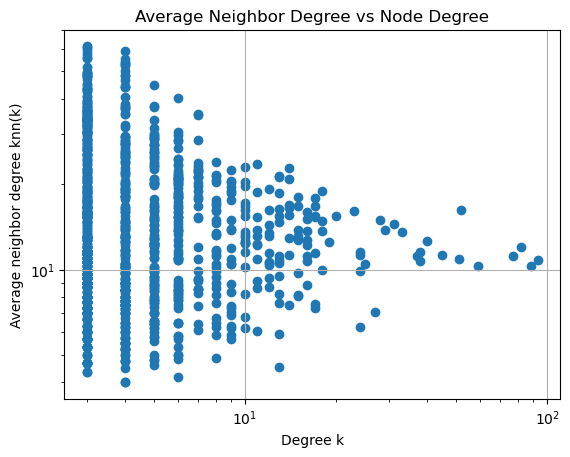

In [16]:
import matplotlib.pyplot as plt

plt.scatter(list(dict(G.degree()).values()), list(knn.values()))
plt.xlabel("Degree k")
plt.ylabel("Average neighbor degree knn(k)")
plt.title("Average Neighbor Degree vs Node Degree")
plt.xscale("log")
plt.yscale("log")
plt.grid(True)
plt.show()

### Task 2: Manipulating Correlations

In [18]:
GAMMA = 3
seq = [int(k) for k in nx.utils.powerlaw_sequence(N, exponent=GAMMA)]
corr_net = nx.random_degree_sequence_graph(seq)

In [19]:
nx.degree_assortativity_coefficient(corr_net)

-0.05641737945527348

In [21]:
def compute_results(G):
    degree_dist = dict(G.degree())
    knn = nx.average_neighbor_degree(G)
    r = nx.degree_assortativity_coefficient(G)
    return degree_dist, knn, r

In [22]:
# Rewiring
import random
def rewire_network(G, increase_assortativity=True, iterations=1000):
    G_rewired = G.copy()
    edges = list(G_rewired.edges())
    r_before = nx.degree_assortativity_coefficient(G_rewired)

    for _ in range(iterations):
        # Refresh edge list
        edges = list(G_rewired.edges())
        
        e1, e2 = random.sample(edges, 2)
        u1, v1 = e1
        u2, v2 = e2

        # Check for loops or multiple edges
        if len({u1, v1, u2, v2}) < 4:
            continue
        
        G_aux = G_rewired.copy()
        G_aux.remove_edge(u1, v1)
        G_aux.remove_edge(u2, v2)
        G_aux.add_edge(u1, u2)
        G_aux.add_edge(v1, v2)      

        r_after = nx.degree_assortativity_coefficient(G_aux)    

        # Decide whether to accept the swap
        if increase_assortativity and r_after > r_before:
            r_before = r_after
            G_rewired = G_aux
                
        if not increase_assortativity and r_after < r_before:
            r_before = r_after
            G_rewired = G_aux

    return G_rewired

In [23]:
# Compare results for graphs with different assortativity
G_assort = rewire_network(corr_net, increase_assortativity=True, iterations=10000)
G_dissort = rewire_network(corr_net, increase_assortativity=False, iterations=10000)


In [29]:
# Compute for your base and rewired graphs
deg_base, knn_base, r_base = compute_results(corr_net)
deg_assort, knn_assort, r_assort = compute_results(G_assort)
deg_diss, knn_diss, r_diss = compute_results(G_dissort)

In [30]:
print("Assortativity coefficients:")
print(f"Base network:          r = {r_base:.3f}")
print(f"More assortative (+r): r = {r_assort:.3f}")
print(f"More disassortative(-r): r = {r_diss:.3f}")

Assortativity coefficients:
Base network:          r = -0.056
More assortative (+r): r = 0.871
More disassortative(-r): r = -0.261


Degree distributions


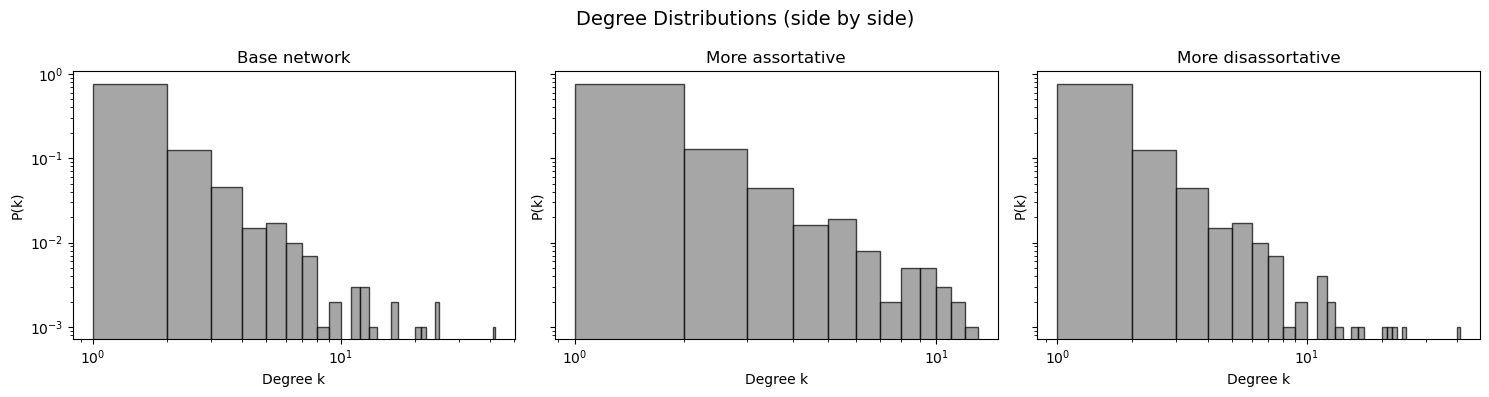

In [31]:
import matplotlib.pyplot as plt

print("Degree distributions")

def plot_degree_distribution(ax, deg_dict, label):
    degrees = list(deg_dict.values())
    ax.hist(
        degrees,
        bins=range(1, max(degrees) + 2),
        density=True,
        alpha=0.7,
        color='gray',
        edgecolor='black'
    )
    ax.set_xlabel("Degree k")
    ax.set_ylabel("P(k)")
    ax.set_title(label)
    ax.set_xscale("log")
    ax.set_yscale("log")  # optional, for power-law visibility

# Create 3 subplots side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

plot_degree_distribution(axes[0], deg_base, "Base network")
plot_degree_distribution(axes[1], deg_assort, "More assortative")
plot_degree_distribution(axes[2], deg_diss, "More disassortative")

plt.suptitle("Degree Distributions (side by side)", fontsize=14)
plt.tight_layout()
plt.show()


Knn distributions


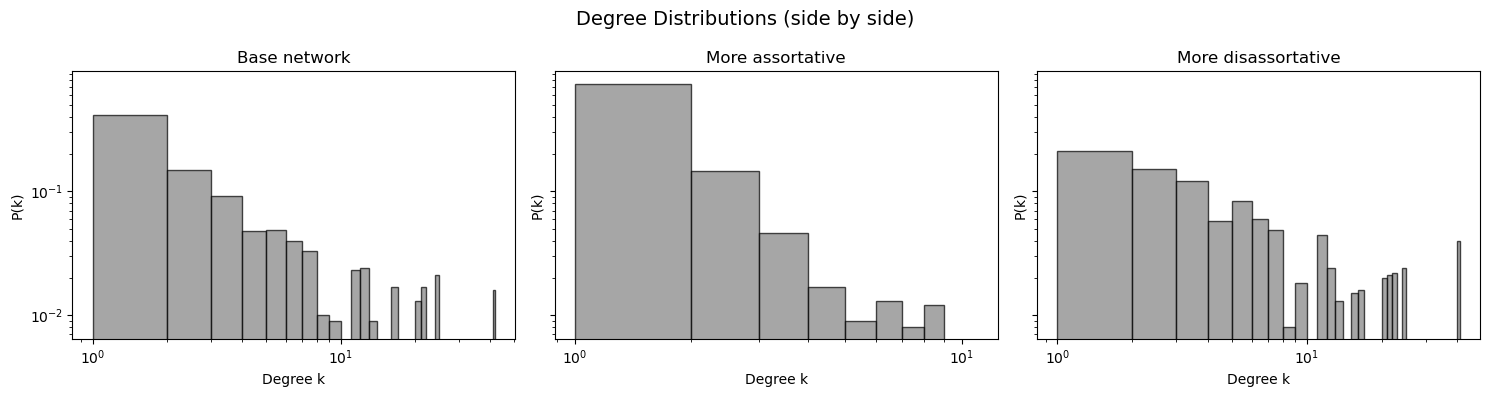

In [43]:
import matplotlib.pyplot as plt
import math
print("Knn distributions")

def plot_degree_distribution(ax, deg_dict, label):
    degrees = list(deg_dict.values())
    ax.hist(
        degrees,
        bins=range(1, math.ceil(max(degrees)) + 2),
        density=True,
        alpha=0.7,
        color='gray',
        edgecolor='black'
    )
    ax.set_xlabel("Degree k")
    ax.set_ylabel("P(k)")
    ax.set_title(label)
    ax.set_xscale("log")
    ax.set_yscale("log")  # optional, for power-law visibility

# Create 3 subplots side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

plot_degree_distribution(axes[0], knn_base, "Base network")
plot_degree_distribution(axes[1], knn_assort, "More assortative")
plot_degree_distribution(axes[2], knn_diss, "More disassortative")

plt.suptitle("Degree Distributions (side by side)", fontsize=14)
plt.tight_layout()
plt.show()

Clustering coefficient increases: assortativity causes high-degree nodes to connect to each other, forming many triangles and dense local structures.

Diameter decreases: the network develops a connected hub-core that shortens global distances.

## Task 3: Correlations in Real Networks

In [48]:
import networkx as nx
import pandas as pd

# Load edges
edges = pd.read_csv("edges.csv")

# Create graph
G = nx.from_pandas_edgelist(edges, source="source", target="target")

In [50]:
deg, knn, r = compute_results(G)

In [53]:
import math
import networkx as nx

def k_cut(G):
    N = G.number_of_nodes()
    avg_k = sum(dict(G.degree()).values()) / N   # ⟨k⟩ = average degree
    return math.sqrt(avg_k * N)


In [54]:
print("Metrics Karate club")
print(f"r: {r}")
print(f"knn: {knn}")
print(f"kcut: {k_cut(G)}")

Metrics Karate club
r: -0.47561309768461413
knn: {0: 4.3125, 1: 5.777777777777778, 2: 6.6, 3: 7.666666666666667, 4: 7.666666666666667, 5: 6.25, 6: 6.25, 7: 10.25, 8: 11.8, 10: 7.666666666666667, 11: 16.0, 12: 11.0, 13: 11.6, 17: 12.5, 19: 14.0, 21: 12.5, 31: 9.0, 30: 10.75, 9: 13.5, 27: 8.75, 28: 11.0, 32: 5.083333333333333, 16: 4.0, 33: 3.823529411764706, 22: 14.5, 23: 8.0, 25: 4.666666666666667, 29: 9.0, 24: 4.333333333333333, 26: 10.5, 14: 14.5, 15: 14.5, 18: 14.5, 20: 14.5}
kcut: 12.489995996796797


In [56]:
G_random = rewire_network(G, increase_assortativity=True, iterations=10000)

deg, knn, r = compute_results(G_random)
print("Metrics Karate club")
print(f"r: {r}")
print(f"knn: {knn}")
print(f"kcut: {k_cut(G_random)}")

Metrics Karate club
r: 0.9463943841735799
knn: {0: 4.0, 1: 4.0, 2: 2.0, 3: 4.0, 4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0, 8: 3.3333333333333335, 10: 2.0, 11: 1.0, 12: 1.0, 13: 1.0, 17: 1.0, 19: 1.0, 21: 1.0, 31: 3.75, 30: 1.0, 9: 1.0, 27: 1.0, 28: 1.0, 32: 3.75, 16: 2.0, 33: 4.0, 22: 2.0, 23: 1.0, 25: 1.0, 29: 1.0, 24: 1.0, 26: 1.0, 14: 1.0, 15: 1.0, 18: 1.0, 20: 1.0}
kcut: 7.483314773547883
